# Modelo SIR para uma epidemia de chikungunya no Recife

**Leandro Cesar**
Elementos de Epidemiologia Computacional, BSI UFRPE

Atividade do Módulo I, revisada depois das anotações da professora. O notebook segue a estrutura dos
cadernos do curso, em R com o pacote `deSolve`, e responde aos seis itens do enunciado na ordem em que
foram pedidos. Os dados do Recife e o modelo com mosquito e latência, que é a base da proposta de
projeto, estão no notebook 02.

| Item | Onde está |
| --- | --- |
| 1. Escolha da doença | Seção 1 |
| 2. Modelagem por SIR | Seção 2 |
| 3. Parâmetros iniciais e justificativa | Seção 3 |
| 4. Implementação e dia do pico | Seção 4 |
| 5. Seis ou mais variações das taxas | Seção 5 |
| 6. Lacunas do modelo | Seção 6 |

### O que mudou depois das anotações

| Anotação | Onde foi respondida |
| --- | --- |
| "Onde está essa discussão?" | Seção 6.1 compara a taxa de ataque do modelo com o inquérito sorológico do próprio Recife |
| "E pode se reinfectar?" | Seção 3 explica o intervalo de geração e a imunidade. A seção 5.5 testa a perda de imunidade |
| "Onde está esse valor?" | Seção 4.1 mostra a tabela simulado contra analítico |
| "Faltaram cenários com gamma maior do que beta" | Seção 5: dez cenários nos três regimes, figura própria para γ ≥ β e mapa de fases |
| "Onde está essa análise?" (controle vetorial) | Seção 5.4: varredura de eficácia e de dia de início do controle |

Também foram corrigidos três pontos encontrados na revisão das fontes. O R0 de 3,4 é de Haider et al.
(2020), e não de Liu et al. O estudo de Magalhaes et al. (2017) foi feito numa unidade de saúde de
Paulista, na Região Metropolitana, e não pela vigilância do Recife. O período infeccioso passou a vir de
uma única fonte, Manore et al. (2014), e por isso γ mudou de 1/7 para 1/6 por dia.

## Preparação

Todo o código do estudo vive em `R/`. O notebook carrega esses arquivos em vez de repetir definições, que
é o mesmo padrão do caderno solução do curso quando ele faz `source("w1_nb4_source_code.R")`.

In [1]:
source("../R/load_all.R")

tamanho_figura()

cat("Pacotes carregados e modelo disponível\n")
cat("População do Recife:", milhares(RECIFE$populacao), "habitantes\n")

Pacotes carregados e modelo disponível


População do Recife: 1.488.920 habitantes


## 1. A doença escolhida

A doença escolhida é a **febre de chikungunya** no município do Recife.

O vírus chegou ao Brasil em 2014. Na Região Metropolitana do Recife, um estudo prospectivo com pacientes
febris atendidos numa unidade de pronto atendimento de Paulista encontrou o primeiro caso de chikungunya
em junho de 2015 e um aumento forte a partir de agosto, ao mesmo tempo em que os casos de zika caíam
(Magalhaes et al., 2017). As notificações do próprio Recife, analisadas no notebook 02, mostram o mesmo
desenho: casos esporádicos no primeiro semestre de 2015, crescimento a partir de agosto e o pico da
primeira onda na semana de 14 de fevereiro de 2016.

Três características tornam a chikungunya adequada para um primeiro modelo SIR:

1. **Quem se recupera fica imune.** A Organização Mundial da Saúde afirma que quem se recupera
   provavelmente fica imune a novas infecções. Há anticorpos neutralizantes 19 anos depois de um surto na
   Tailândia (Nitatpattana et al., 2014), e numa coorte nas Filipinas ninguém que já tinha esses
   anticorpos se infectou em dois anos de acompanhamento (Srikiatkhachorn et al., 2016). Isso justifica um
   compartimento R sem retorno para S.
2. **A população era virgem.** O vírus não circulava no Recife antes de 2015. Começar com toda a população
   em S e um único caso em I descreve a introdução real, e não só uma idealização didática.
3. **A primeira onda é bem delimitada no tempo**, entre 2015 e 2016, o que permite descrevê-la sem modelar
   reintroduções.

A simplificação central, retomada na seção 6, é que o mosquito *Aedes aegypti* não aparece no modelo. A
transmissão é tratada como se fosse de pessoa para pessoa, e o mosquito fica escondido dentro da taxa de
contágio.

## 2. O modelo SIR

A população de tamanho $N$ é dividida em suscetíveis $S$, infectados $I$ e recuperados $R$. A força de
infecção é dinâmica, isto é, depende da fração da população infectada no instante considerado, como no
caderno 4 do curso.

$$\lambda = \beta \frac{I}{N}$$

$$\frac{dS}{dt} = -\lambda S \qquad
\frac{dI}{dt} = \lambda S - \gamma I \qquad
\frac{dR}{dt} = \gamma I$$

O número básico de reprodução é a razão entre as duas taxas, $R_0 = \beta / \gamma$: o número médio de
pessoas que um infectado contamina enquanto está infeccioso, numa população toda suscetível.

### Hipóteses assumidas

| Hipótese | O que significa aqui |
| --- | --- |
| População homogênea | Todos no mesmo compartimento correm o mesmo risco |
| Mistura homogênea | Qualquer suscetível pode encontrar qualquer infectado, com a mesma probabilidade |
| População fechada | Sem nascimentos, óbitos ou migração, então `S + I + R = N` em todo instante |
| Imunidade permanente | Quem entra em R não retorna a S |
| Infecciosidade imediata | Não há período de latência, quem é infectado já transmite |
| Taxas constantes | `beta` e `gamma` não variam ao longo do surto |

O modelo é escrito com a força de infecção injetada como função. O caderno 3 do curso usa `lambda`
constante e o caderno 4 usa `lambda = beta * I / N`, e uma única definição atende aos dois casos. O mesmo
arquivo traz as duas extensões usadas na seção 5: o controle vetorial que começa num dia escolhido e a
taxa `omega` de perda de imunidade. Com os valores padrão, sem controle e com `omega` igual a zero, o
modelo é exatamente o SIR do curso.

In [2]:
cat(readLines("../R/sir_model.R"), sep = "\n")

# Modelo SIR do Módulo I do curso, com a força de infecção injetada como estratégia.
#
# O notebook 3 usa lambda constante e o notebook 4 usa lambda = beta * I / N.
# As duas versões diferem apenas nesse ponto, então a força de infecção entra
# como função e o restante do modelo permanece único.

# Estratégia do notebook 3: lambda fixo, independente da prevalência.
foi_constante <- function(time, state, parameters) {
  parameters[["lambda"]]
}

# Estratégia do notebook 4: lambda proporcional à fração infectada.
foi_dinamica <- function(time, state, parameters) {
  N <- sum(state[c("S", "I", "R")])
  parameters[["beta"]] * state[["I"]] / N
}

# Controle vetorial implícito: a partir do dia `inicio`, o contágio cai pela
# fração `eficacia`. Em Ross e Macdonald, beta é proporcional à densidade de
# mosquitos, então reduzir beta equivale a reduzir essa densidade.
foi_com_controle <- function(eficacia, inicio = 0) {
  function(time, state, parameters) {
    reducao <- if (time >= inicio) efi

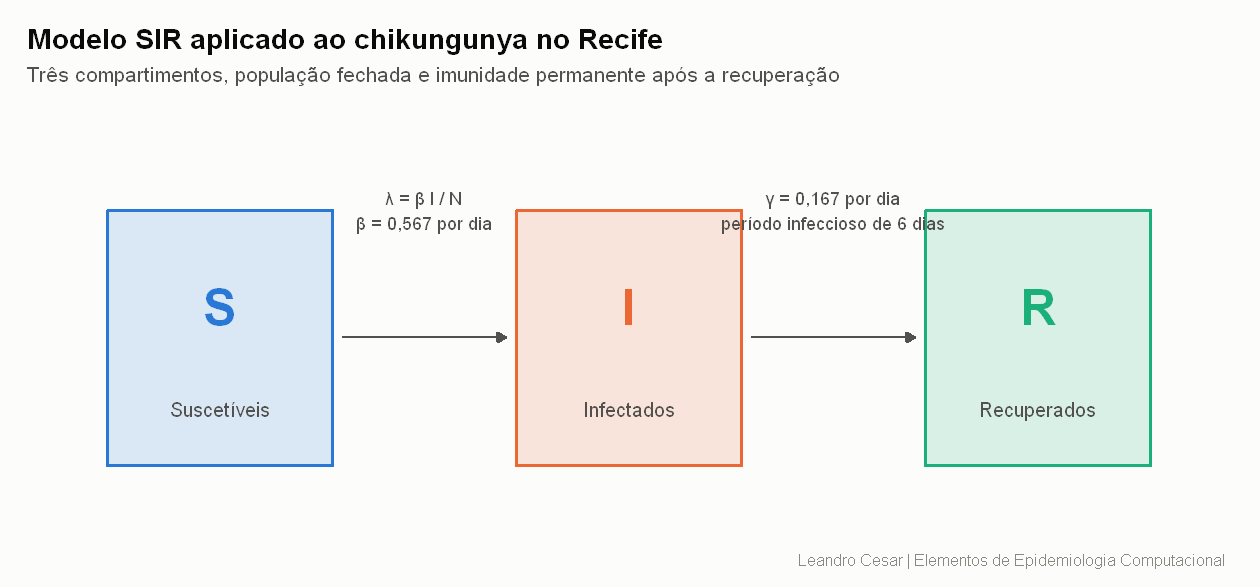

In [3]:
tamanho_figura(9, 4.2)
figura_diagrama()

## 3. Parâmetros iniciais e justificativa

| Parâmetro | Valor | Justificativa |
| --- | --- | --- |
| `N` | 1.488.920 | População do Recife no Censo 2022 do IBGE |
| `S0` | `N - 1` | Nenhuma imunidade ao chikungunya antes de 2015 |
| `I0` | 1 | Um único caso introduzido, mesma premissa do caderno do curso |
| `R(0)` | 0 | Ninguém recuperado no instante da introdução |
| `gamma` | 1/6 por dia | Período infeccioso de 6 dias, valor base de Manore et al. (2014), que usam a faixa de 3 a 7 dias |
| `R0` | 3,4 | Média ponderada de surtos transmitidos por *Aedes*, intervalo de 95 por cento entre 2,4 e 4,2 (Haider et al., 2020) |
| `beta` | `R0 * gamma` = 0,567 por dia | Derivado de R0, não arbitrado |
| Horizonte | 180 dias | Suficiente para o surto terminar com esses valores |

**Por que γ vem do período infeccioso.** γ é o inverso do tempo em que a pessoa infectada consegue passar
o vírus adiante. Na chikungunya, é o tempo em que ela tem vírus no sangue e infecta o mosquito que a
pica. Como o modelo não tem mosquito, ele ignora os dias que o vírus passa dentro do mosquito antes de
chegar à próxima pessoa. Por isso o **intervalo de geração** do modelo, que é o tempo entre a infecção de
uma pessoa e a infecção da pessoa seguinte na cadeia de transmissão, sai mais curto do que o real, e a
epidemia simulada corre mais rápido do que a observada. Não se trata da mesma pessoa infectada duas
vezes: são duas pessoas diferentes, uma depois da outra. O cenário 10 da seção 5 mostra o efeito de mudar
esse ritmo, e o notebook 02 mostra o mesmo efeito com o mosquito explícito.

**A mesma pessoa pode se infectar de novo?** No modelo, não: quem entra em R fica em R. A escolha se apoia
em três evidências. A OMS afirma que quem se recupera provavelmente fica imune. Os anticorpos
neutralizantes persistem por décadas (Nitatpattana et al., 2014) e protegem: ninguém que os tinha se
infectou na coorte de Cebu (Srikiatkhachorn et al., 2016). E o vírus tem um só sorotipo, com proteção
cruzada entre os genótipos (Auerswald et al., 2018). Esse é um contraste importante com a dengue, que tem
quatro tipos de vírus, e a proteção contra os outros tipos dura só de meses a anos (CDC). Por isso um SIR
serve para a chikungunya e não serviria para a dengue. A seção 5.5 mostra o que mudaria se a imunidade
durasse poucos anos.

**Por que β vem de R0.** Em vez de escolher uma taxa de contágio diretamente, ela é obtida de R0, que é a
grandeza que os estudos estimam a partir de surtos reais. Haider et al. (2020) reuniram essas estimativas
e chegaram à média de 3,4, com 4,1 quando o vetor é só o *Aedes aegypti*. Adotou-se a média geral, e a
faixa de 2,4 a 4,2 é usada na análise de controle da seção 5.4.

In [4]:
parametros <- data.frame(
  Parametro = c("N", "S0", "I0", "R(0)", "beta", "gamma", "R0", "Horizonte"),
  Valor = c(milhares(RECIFE$populacao),
            milhares(BASELINE$S0),
            BASELINE$I0,
            BASELINE$R0_compartimento,
            num_br(CHIKV$beta, 3),
            num_br(CHIKV$gamma, 3),
            num_br(CHIKV$R0, 1),
            paste(BASELINE$duracao_dias, "dias"))
)
parametros

Parametro,Valor
<chr>,<chr>
N,1.488.920
S0,1.488.919
I0,1
R(0),0
beta,"0,567"
gamma,"0,167"
R0,"3,4"
Horizonte,180 dias


## 4. Implementação e dia do pico

A integração numérica usa `deSolve::ode`, chamada por meio de `run_sir_model`, que é a mesma fachada usada
no caderno 4 do curso.

In [5]:
sim <- run_sir_model(beta = CHIKV$beta, gamma = CHIKV$gamma)

head(sim$wide, 10)

,time,S,I,R
,<dbl>,<dbl>,<dbl>,<dbl>
1,0,1488919,1.000000,0.0000000
2,1,1488918,1.491826,0.2049278
3,2,1488917,2.225542,0.5106433
4,3,1488916,3.320115,0.9667169
5,4,1488913,4.953021,1.6470982
6,5,1488910,7.389024,2.6621074
7,6,1488905,11.023073,4.1763125
8,7,1488897,16.444383,6.4352326
9,8,1488886,24.531881,9.8051154


In [6]:
resumo <- epidemic_summary(sim, "Linha de base")

resumo[, c("dia_pico", "S_pico", "I_pico", "R_pico", "prevalencia_pico", "taxa_ataque")]

dia_pico,S_pico,I_pico,R_pico,prevalencia_pico,taxa_ataque
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
38,438145.6,515089.9,535684.5,0.3459487,0.9620277


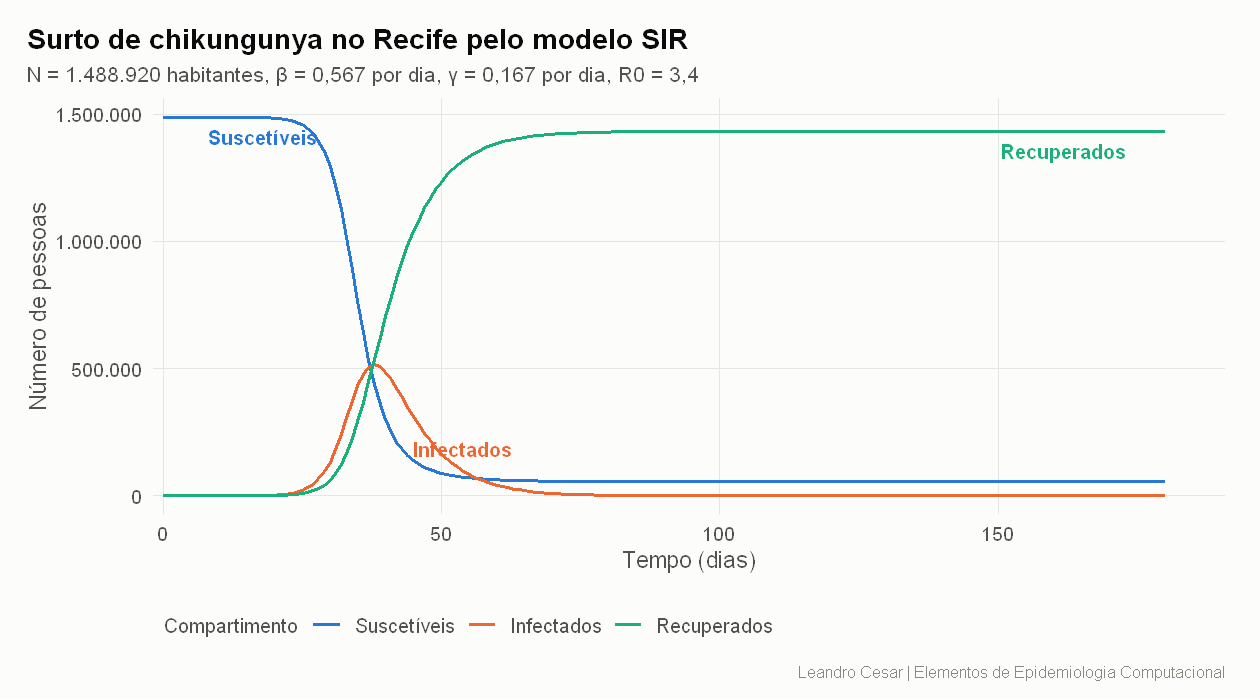

In [7]:
tamanho_figura(9, 5)
figura_linha_base(sim)

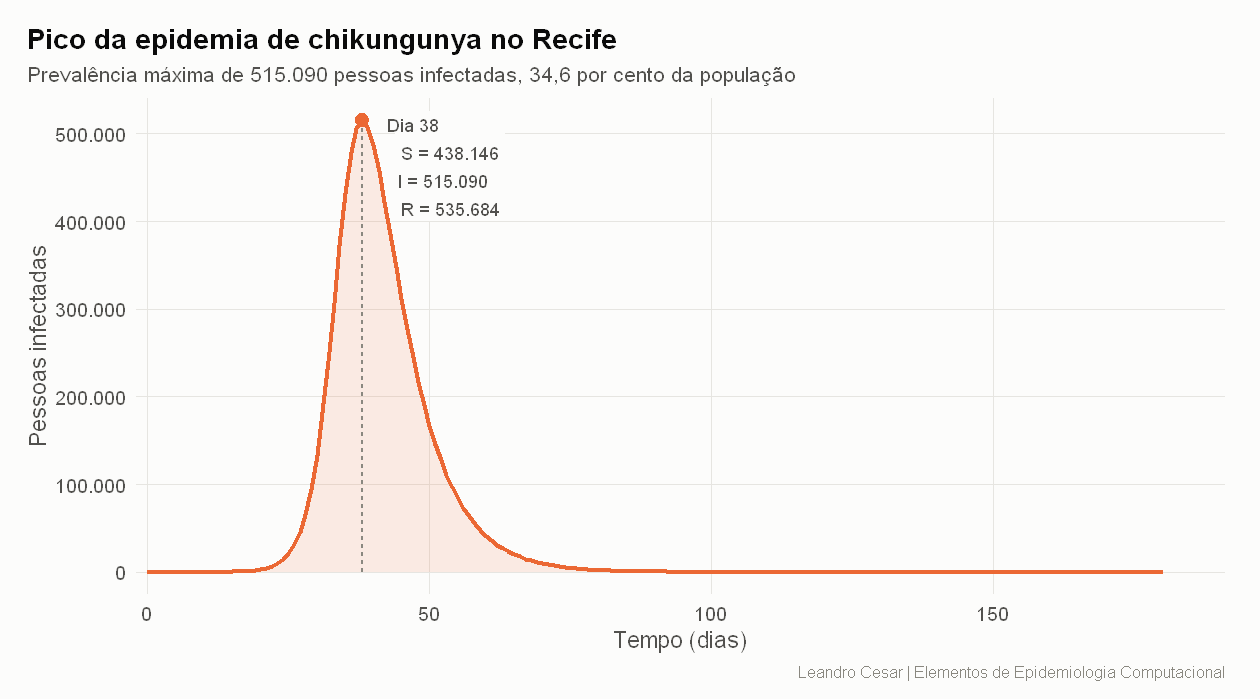

In [8]:
figura_pico(sim, resumo)

### Resposta ao item 4

**A epidemia atinge o pico no dia 38.** Nesse dia os compartimentos contêm:

| Compartimento | Pessoas | Fração da população |
| --- | --- | --- |
| Suscetíveis | 438.146 | 29,4 por cento |
| Infectados | 515.090 | 34,6 por cento |
| Recuperados | 535.684 | 36,0 por cento |

### 4.1 Conferência com a teoria

O SIR tem três resultados que podem ser calculados sem simular, e eles servem para conferir a
implementação.

- **Suscetíveis no pico.** No pico, $I$ para de crescer, então $dI/dt = 0$, o que dá $\beta S / N =
  \gamma$, ou seja, $S = N / R_0$. O pico acontece exatamente quando a reserva de suscetíveis cruza esse
  limiar.
- **Prevalência máxima.** Integrando as equações, a fração infectada no pico é
  $I_{max}/N = 1 - (1 + \ln R_0)/R_0$.
- **Taxa de ataque final.** A fração $a$ da população que se infecta até o fim do surto satisfaz
  $1 - a = e^{-R_0 a}$. Essa equação não tem solução em fórmula fechada, então a raiz é encontrada
  numericamente com `uniroot`, a busca de raiz do R.

A tabela abaixo mostra os três valores, simulados e analíticos, com sete algarismos significativos.

In [9]:
validacao <- validacao_sir(sim)
data.frame(
  Grandeza = validacao$grandeza,
  Expressao = validacao$expressao,
  Simulado = formatC(validacao$simulado, digits = 7, format = "g", decimal.mark = ","),
  Analitico = formatC(validacao$analitico, digits = 7, format = "g", decimal.mark = ","),
  `Erro relativo` = formatC(validacao$erro_relativo, digits = 2, format = "e"),
  check.names = FALSE
)

Grandeza,Expressao,Simulado,Analitico,Erro relativo
<chr>,<chr>,<chr>,<chr>,<chr>
Prevalência no pico (pessoas),N (1 - (1 + ln R0) / R0),"515089,7","515089,5",4.55e-07
Suscetíveis no pico (pessoas),N / R0,"438146,9","437917,6",5.24e-04
Taxa de ataque final (fração),raiz de 1 - a = exp(-R0 a),"0,9620277","0,9620275",1.45e-07


A taxa de ataque simulada é 0,9620277 e a raiz da equação é 0,9620275. Arredondados na sexta casa
decimal, os dois valores são 0,962028, e o erro relativo é de 1,4 × 10⁻⁷. A prevalência no pico também
coincide, com erro relativo de 5 × 10⁻⁷. O número de suscetíveis no pico difere 0,05 por cento porque o
instante do pico é procurado numa malha de 0,05 dia, e perto do pico S cai muito depressa. O script
`scripts/render_figures.R` repete essas conferências toda vez que as figuras são geradas e falha se alguma
divergir mais de 1 por cento.

## 5. Variações nas taxas de contágio e de recuperação

O enunciado pede taxas iguais e uma taxa fixa com a outra variando. Os dez cenários abaixo cruzam essas
situações com os três regimes possíveis: contágio maior que recuperação (β > γ), taxas iguais (β = γ) e
recuperação maior que contágio (β < γ, isto é, γ > β).

| Família | Cenários | Regimes cobertos |
| --- | --- | --- |
| Referência | 1 | β > γ |
| γ fixo, β varia | 2, 3, 4, 5 | β > γ, β = γ, γ > β |
| β fixo, γ varia | 6, 7, 8, 9 | β > γ, β = γ, γ > β |
| Mesmo R0, ritmo pela metade | 10 | β > γ |

In [10]:
cenarios <- run_scenarios()

tabela <- with(cenarios$resumo, data.frame(
  ID = id,
  `Cenário` = as.character(cenario),
  Regime = regime,
  beta = num_br(beta, 3),
  gamma = num_br(gamma, 3),
  R0 = num_br(R0, 2),
  `Dia do pico` = ifelse(R0 > 1, as.character(dia_pico), "sem surto"),
  `Infectados no pico` = ifelse(R0 > 1, milhares(I_pico), "sem surto"),
  `Total infectado` = ifelse(R0 > 1, milhares(infectados_total), num_br(infectados_total, 1)),
  `Ataque final` = paste0(num_br(100 * taxa_ataque, 1), " por cento"),
  check.names = FALSE
))
tabela

ID,Cenário,Regime,beta,gamma,R0,Dia do pico,Infectados no pico,Total infectado,Ataque final
<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,Linha de base,β > γ,"0,567","0,167","3,40",38,515.090,1.432.382,"96,2 por cento"
2,Contágio 50 por cento maior,β > γ,"0,850","0,167","5,10",23,720.957,1.479.546,"99,4 por cento"
3,Contágio pela metade,β > γ,"0,283","0,167","1,70",116,148.328,1.029.121,"69,1 por cento"
4,Contágio igual à recuperação,β = γ,"0,167","0,167","1,00",sem surto,sem surto,"61,8","0,0 por cento"
5,Contágio na metade da recuperação,β < γ,"0,083","0,167","0,50",sem surto,sem surto,"2,0","0,0 por cento"
6,Período infeccioso dobrado,β > γ,"0,567","0,083","6,80",33,847.936,1.487.249,"99,9 por cento"
7,Recuperação igual ao contágio,β = γ,"0,567","0,567","1,00",sem surto,sem surto,"206,8","0,0 por cento"
8,Recuperação acima do contágio,β < γ,"0,567","0,708","0,80",sem surto,sem surto,"5,0","0,0 por cento"
9,Recuperação no dobro do contágio,β < γ,"0,567","1,133","0,50",sem surto,sem surto,"2,0","0,0 por cento"


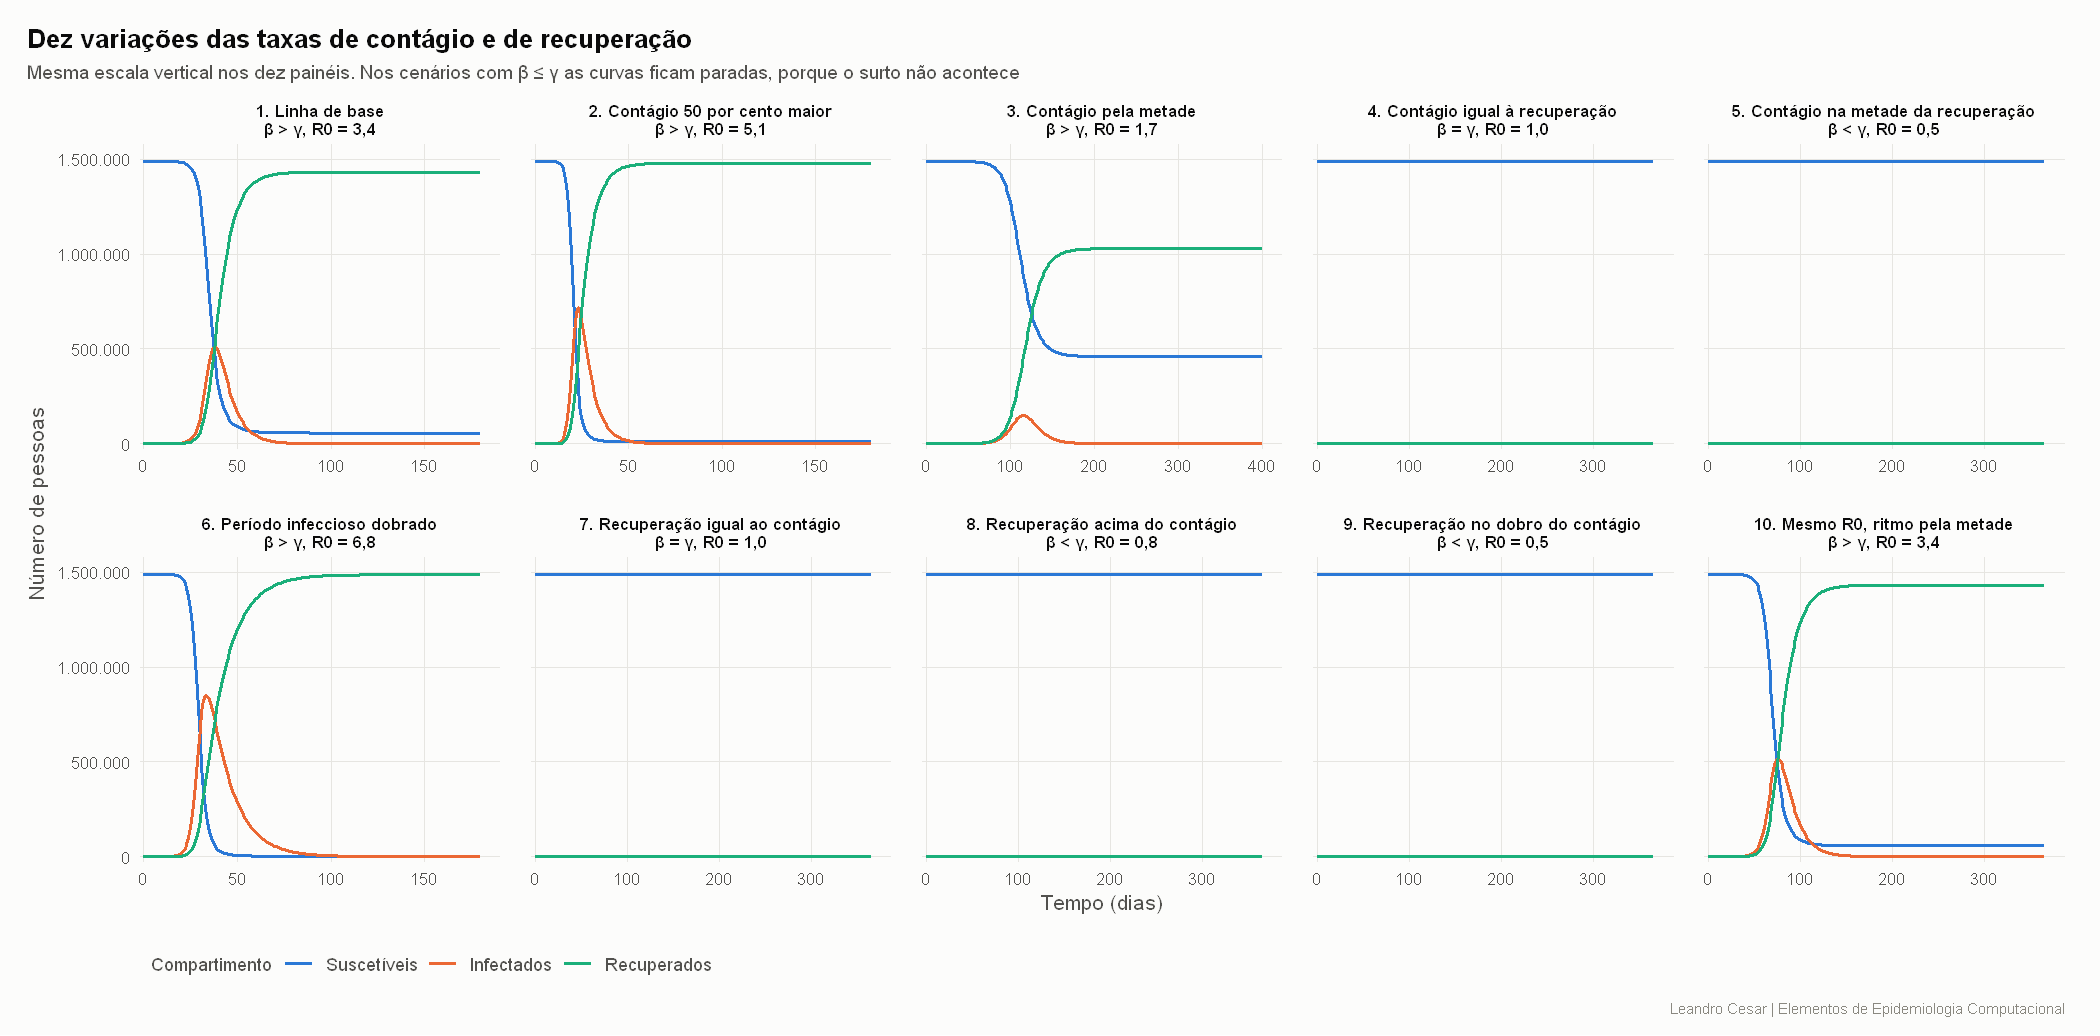

In [11]:
tamanho_figura(15, 7.4)
figura_cenarios_painel(cenarios$curvas, cenarios$resumo)

### 5.1 Quando há surto, β > γ

**Recuperação fixa, contágio variando (cenários 1, 2 e 3).** Aumentar o contágio adianta e agrava o surto.
Com β 50 por cento maior, R0 vai a 5,1 e o pico vem no dia 23 com 720.957 infectados. Com β pela metade,
R0 cai para 1,7 e o pico só chega no dia 116, com 148.328 infectados. A curva também muda de largura:
quanto mais rápido o surto sobe, mais rápido ele esgota os suscetíveis e desce.

**Contágio fixo, recuperação variando (cenário 6).** A taxa de recuperação age no sentido oposto. Dobrar o
período infeccioso de 6 para 12 dias dobra R0 para 6,8, e o pico chega a 847.936 pessoas no dia 33.

**Mesmo R0 com ritmo pela metade (cenário 10).** Dividindo β e γ pelo mesmo fator, R0 continua 3,4. A
altura do pico e a taxa de ataque ficam idênticas às da linha de base, mas o pico passa do dia 38 para o
dia 76, exatamente o dobro. **A razão entre as taxas determina o tamanho da epidemia, e a escala das taxas
determina só a sua velocidade.** É por isso que o intervalo de geração curto, discutido na seção 3, afeta
o calendário do surto mas não o número de pessoas atingidas.

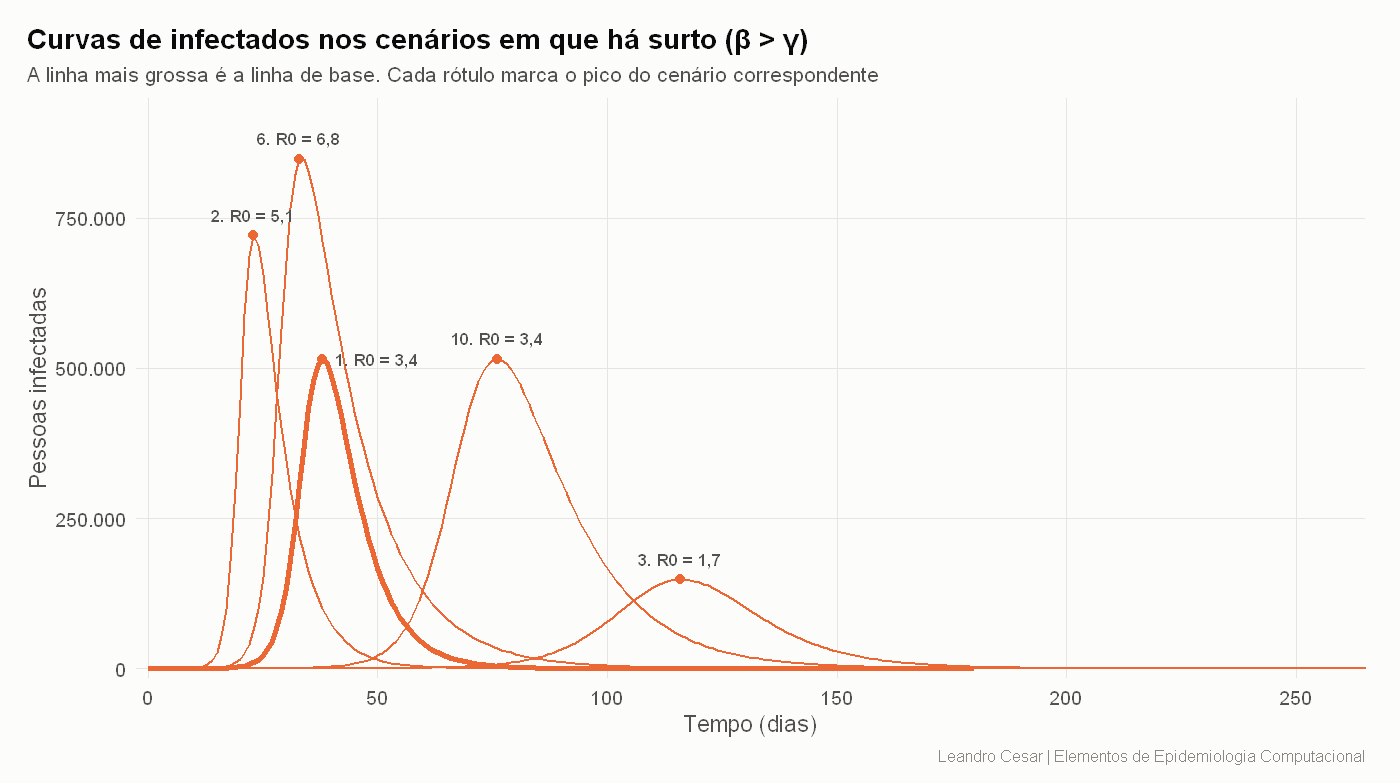

In [12]:
tamanho_figura(10, 5.6)
figura_cenarios_infectados(cenarios$curvas, cenarios$resumo)

### 5.2 Quando γ ≥ β, não há surto

γ maior que β quer dizer que a pessoa se recupera, em média, antes de passar o vírus para uma outra. No
início, com quase todos suscetíveis, $S \approx N$ e a equação de $I$ vira $dI/dt = (\beta - \gamma) I$,
cuja solução é $I(t) = I_0 e^{(\beta - \gamma) t}$. Com γ > β o expoente é negativo e a infecção some.
Numa escala logarítmica essa solução é uma reta, e a figura abaixo mostra que a simulação cai exatamente
sobre ela.

Também dá para contar quantas pessoas se infectam até a cadeia acabar. O caso inicial gera em média R0
casos, que geram R0² casos, e assim por diante. A soma dessa série é $I_0 / (1 - R_0)$: **2 pessoas** para
R0 = 0,5 (cenários 5 e 9) e **5 pessoas** para R0 = 0,8 (cenário 8). A tabela da seção 5 confirma esses
totais.

Os cenários 5 e 9 têm o mesmo R0 = 0,5 e o mesmo total de 2 infectados, mas o 9 se extingue muito mais
rápido, porque suas taxas são maiores. É a mesma regra da seção 5.1 valendo abaixo do limiar.

**Taxas iguais (cenários 4 e 7).** Com β = γ, R0 = 1 e a prevalência não cresce nem decai: cada infectado
é substituído por exatamente um novo infectado. O total infectado cresce devagar, em linha reta, como
$I_0 (1 + \beta t)$: 62 pessoas num ano no cenário 4 e
cerca de 207 no cenário 7. É o limiar epidêmico, e ele separa
dois comportamentos diferentes, não apenas dois surtos de tamanhos diferentes.

Valores de I abaixo de 1 representam a média esperada. Na prática, quando a média fica abaixo de uma
pessoa, a cadeia de transmissão já se encerrou.

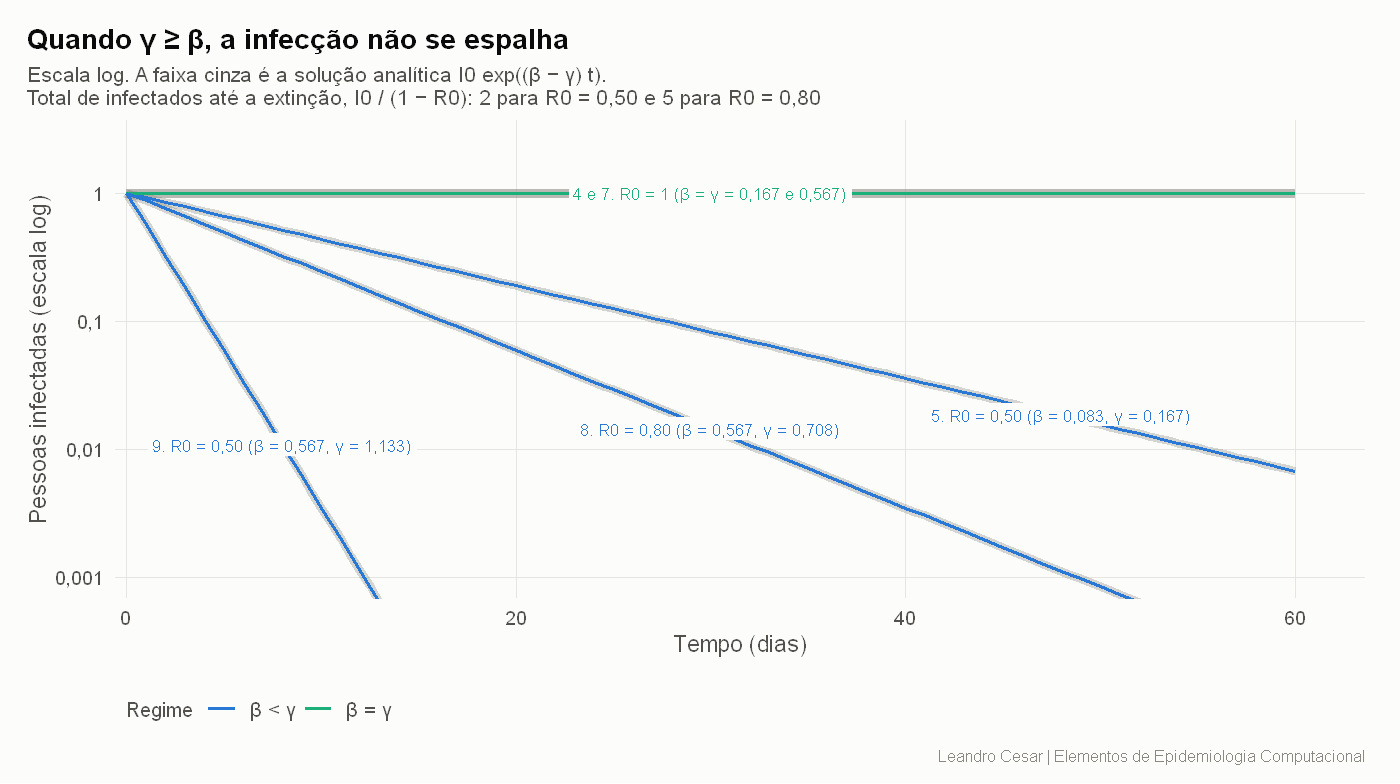

In [13]:
figura_regime_subcritico(cenarios$curvas, cenarios$resumo)

### 5.3 Todas as combinações de β e γ

O mapa abaixo calcula a taxa de ataque final para cada par (γ, β), usando a equação do tamanho final da
seção 4.1. Os dez cenários estão marcados com seus números. Toda a região abaixo da diagonal, onde γ > β,
tem taxa de ataque zero. Acima dela, a taxa de ataque depende só da inclinação da reta que passa pela
origem, que é R0, e por isso as cores formam leques a partir da origem.

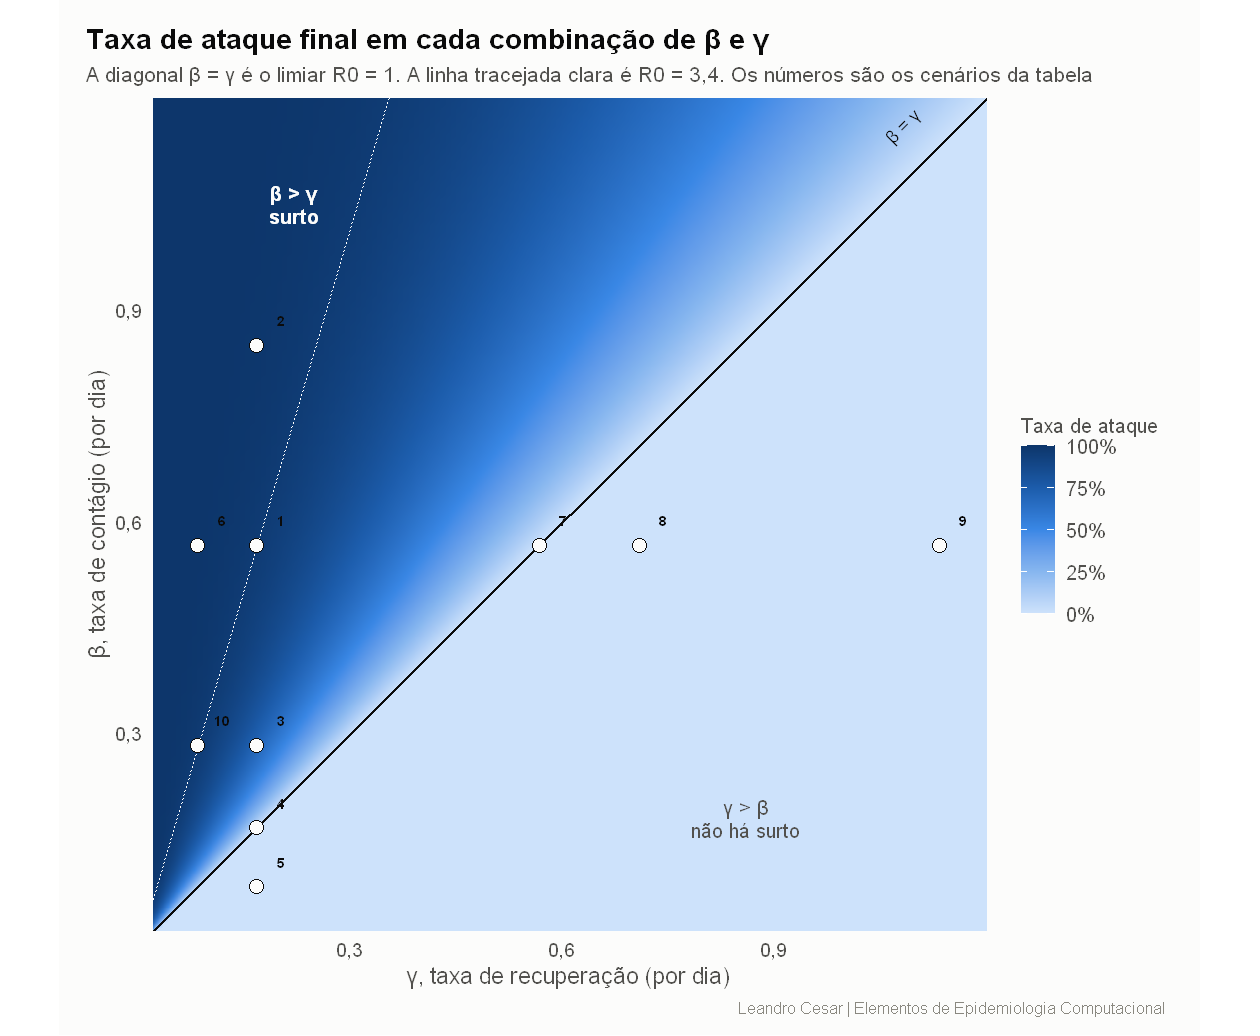

In [14]:
tamanho_figura(9, 7.4)
grade <- grade_fases(betas = seq(0.01, 1.2, length.out = 160),
                     gammas = seq(0.01, 1.2, length.out = 160))
figura_mapa_fases(grade, cenarios$resumo)

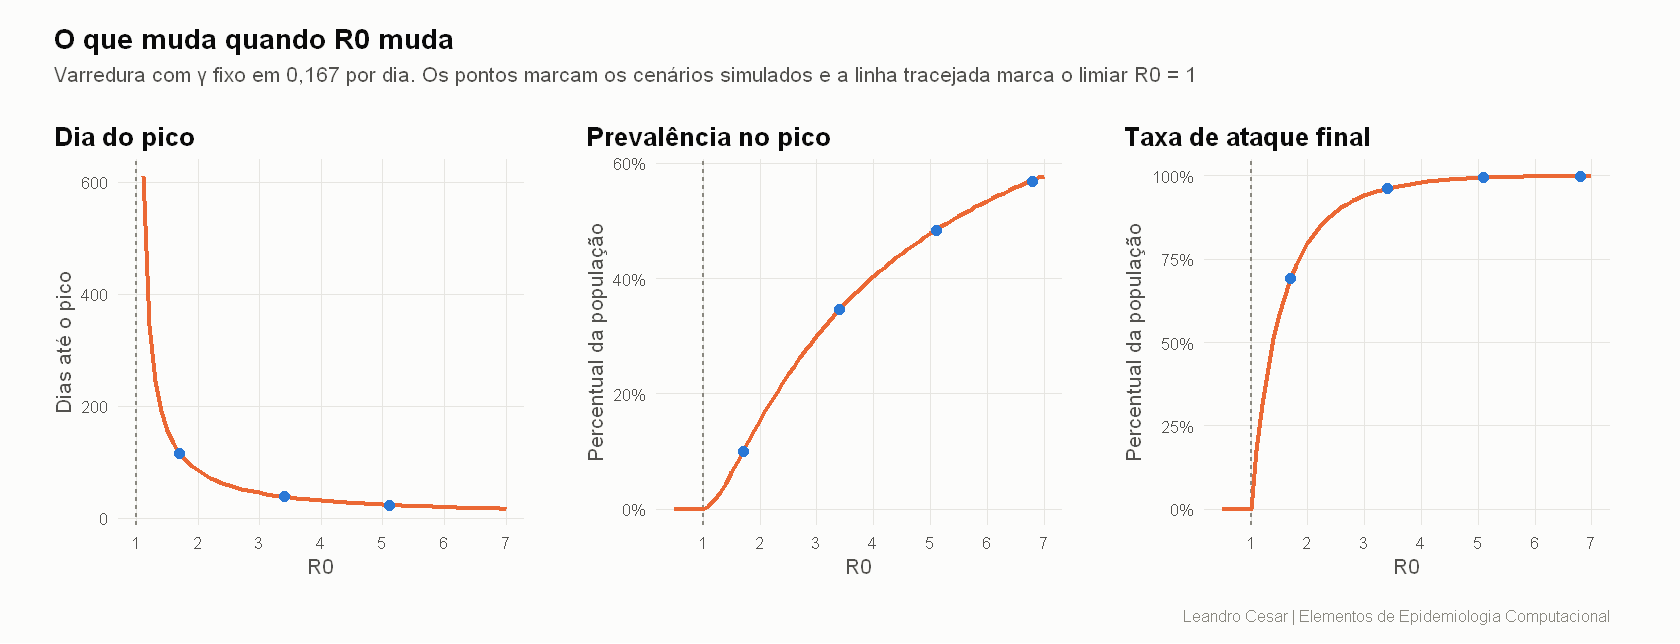

In [15]:
tamanho_figura(12, 4.6)
figura_limiar(cenarios$resumo)

**Leitura conjunta.** A prevalência no pico e a taxa de ataque final dependem apenas de R0, e as duas
crescem rápido logo acima do limiar e depois saturam. Já o dia do pico depende também da escala das
taxas, e por isso só os cenários com o mesmo γ aparecem no primeiro painel. Uma mesma redução de R0 vale
muito quando R0 está perto de 1 e quase nada quando está acima de 4.

### 5.4 Controle vetorial

No SIR não existe mosquito, então o controle vetorial só pode ser representado como uma redução de β. Essa
representação tem uma justificativa: na teoria de Ross e Macdonald, a transmissão é proporcional à
densidade de mosquitos por pessoa (Smith et al., 2012), de modo que eliminar uma fração dos mosquitos
reduz β na mesma fração.

O que não existe é um valor bem estabelecido para a eficácia de uma campanha real. A revisão sistemática
de Bowman et al. (2016) encontrou apenas dois ensaios randomizados que mediram a incidência de dengue, e
nenhum mostrou efeito significativo. O melhor resultado foi o do manejo ambiental comunitário com tampas
nos reservatórios de água, com razão de chances de 0,22. Por isso a análise não fixa uma eficácia: ela
varia a eficácia e o dia de início e mostra o resultado de cada combinação.

**Eficácia.** O controle impede o surto quando leva R0 abaixo de 1, o que exige reduzir o contágio em
pelo menos $1 - 1/R_0$. Com R0 = 3,4, a eficácia crítica é de 70,6 por cento. Na faixa de Haider et al.,
ela vai de 58,3 por cento (R0 = 2,4) a 76,2 por cento (R0 = 4,2). Abaixo da eficácia crítica o surto
acontece, só que menor: uma redução de 60 por cento desde o primeiro caso leva a taxa de ataque a 47,8 por
cento, com pico de 57.492 infectados no dia 208.

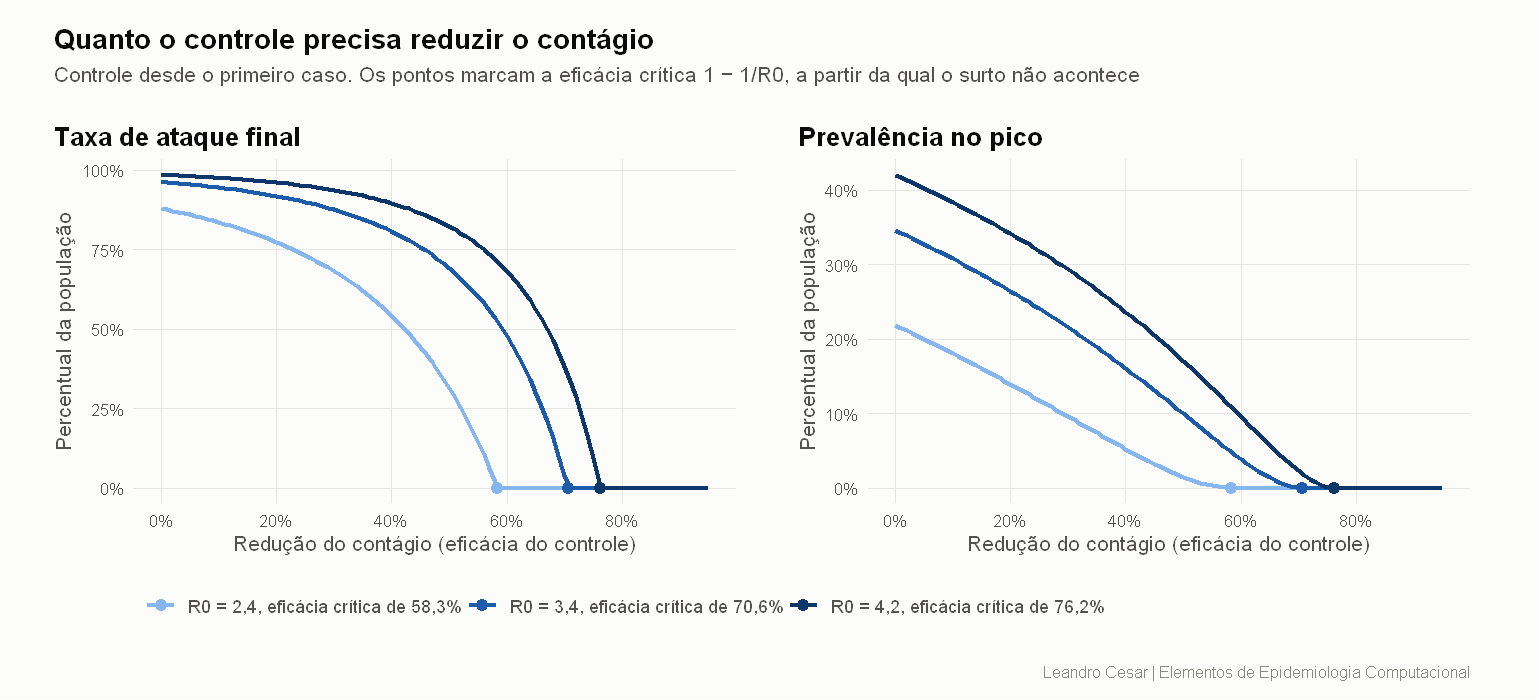

In [16]:
tamanho_figura(11, 5)
figura_controle_eficacia(varredura_eficacia())

**Dia de início.** A segunda figura simula o controle começando em dias diferentes. Uma redução de 80 por
cento, acima da eficácia crítica, impede o surto se começar no dia 0, deixa a taxa de ataque em 0,7 por
cento se começar no dia 20 e em 24 por cento no dia 30. Iniciada no dia 40, logo depois do pico, a mesma
redução deixa 84 por cento da população infectada, contra 96 por cento sem controle. É essa simulação que
sustenta a frase "intervenções valem mais quando aplicadas cedo".

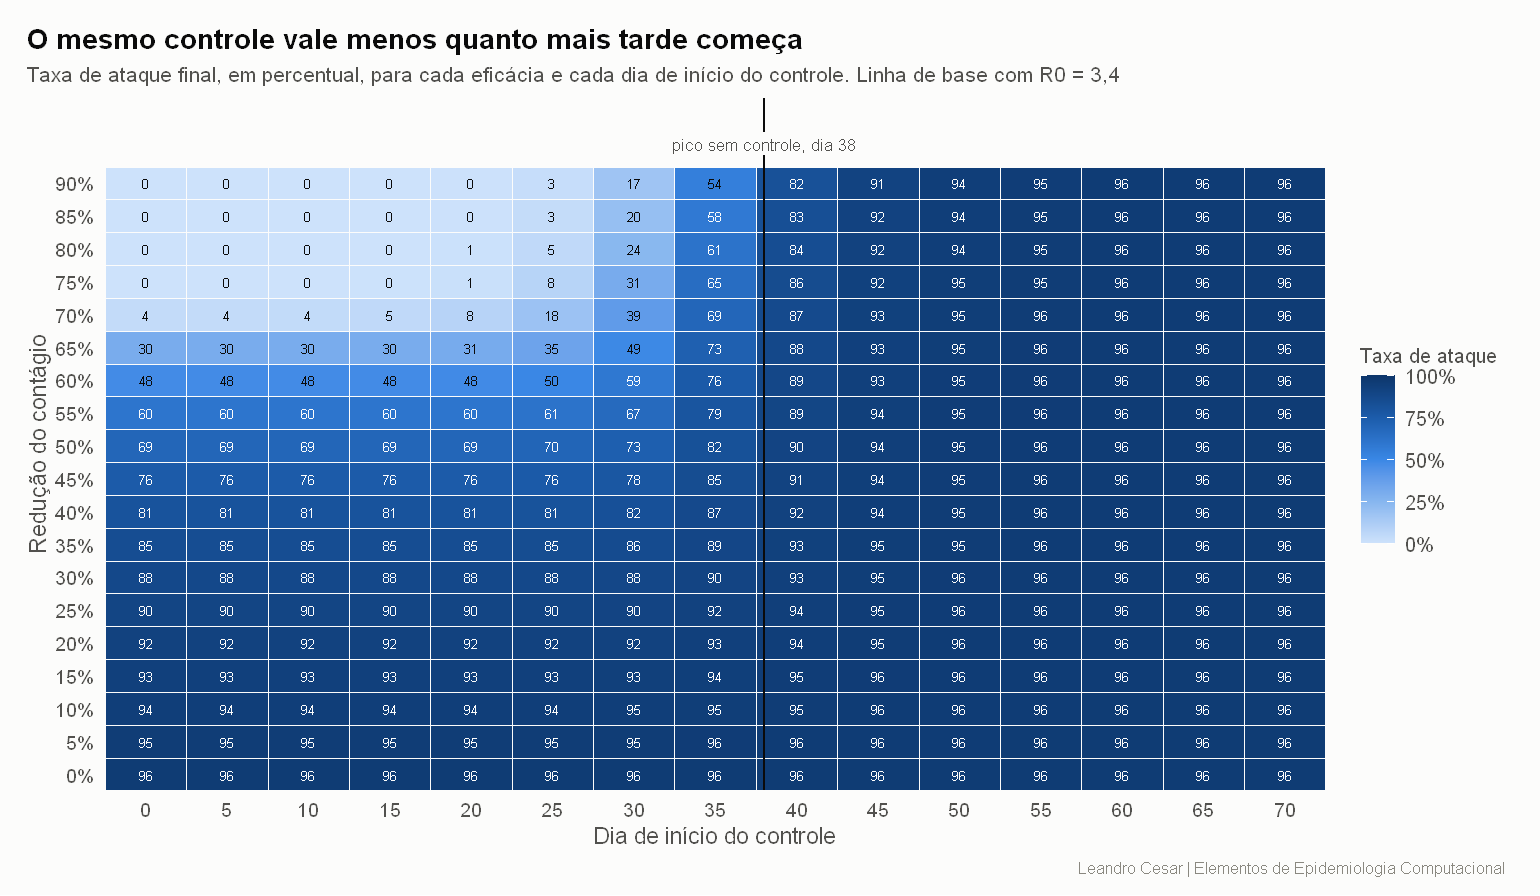

In [17]:
tamanho_figura(11, 6.4)
inicio_grade <- varredura_inicio(duracao = 5000)
figura_controle_inicio(inicio_grade, resumo$dia_pico)

### 5.5 E se a imunidade não fosse permanente?

Para responder à pergunta sobre reinfecção com o próprio modelo, acrescenta-se a taxa ω de perda de
imunidade, e o SIR vira SIRS:

$$\frac{dS}{dt} = -\lambda S + \omega R \qquad \frac{dR}{dt} = \gamma I - \omega R$$

A duração média da imunidade é $1/\omega$. Com imunidade de 10 anos em média, os suscetíveis voltam a passar
de $N/R_0$ e uma segunda onda aparece por volta do dia 2.451, perto de 6,7 anos depois, com 74 mil
infectados no pico. Com imunidade de 2 anos, a segunda onda vem em 1,5 ano e a doença fica endêmica, com
cerca de 8.600 pessoas infectadas a qualquer momento. Com imunidade permanente não há segunda onda.

O Recife teve uma segunda onda grande em 2021, cinco anos depois da primeira. Ela poderia ser sinal de
reinfecção? O inquérito sorológico de 2018 e 2019 mostra que não é preciso supor isso: cerca de 64 por
cento da população ainda não tinha anticorpos (seção 6.1), ou seja, sobravam suscetíveis de sobra sem que
ninguém perdesse a imunidade. Somado às evidências da seção 3, isso mantém R como compartimento
permanente. A explicação para 2021 está em outra hipótese do modelo, a mistura homogênea, discutida a
seguir.

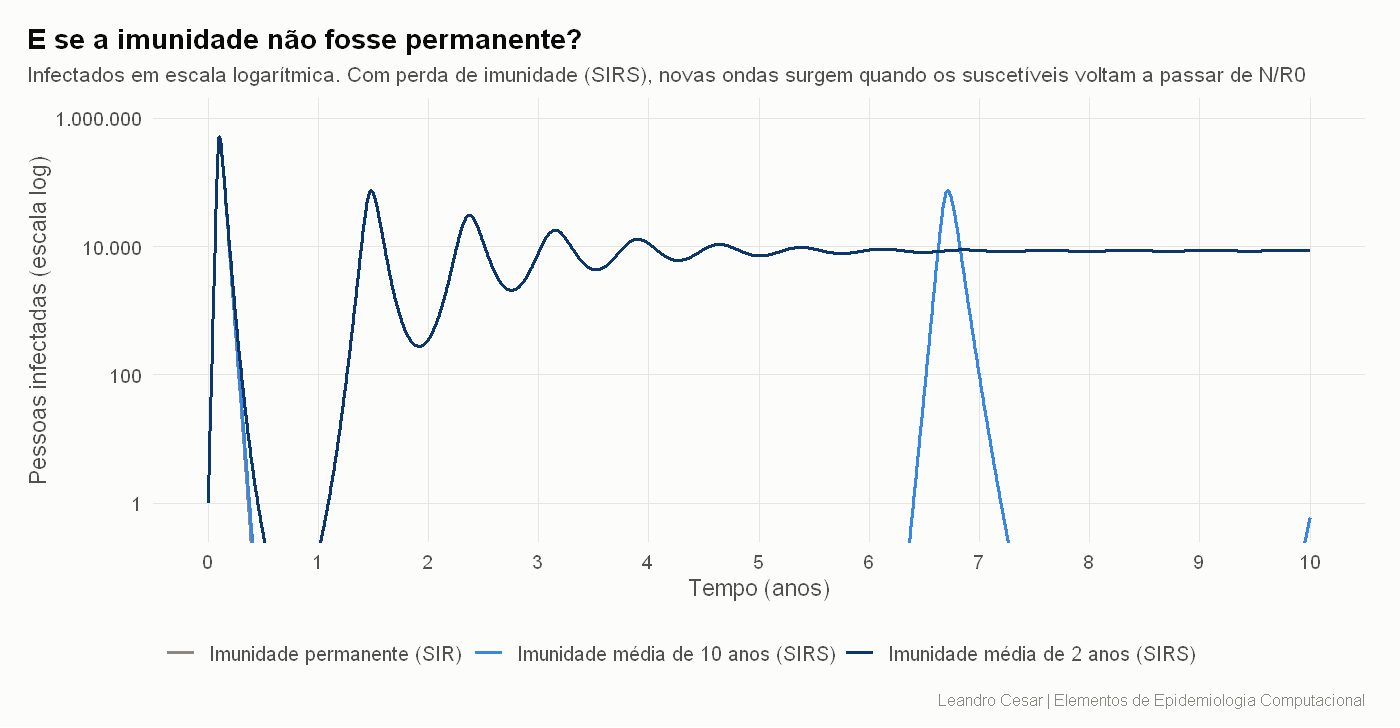

In [18]:
tamanho_figura(10, 5.2)
figura_imunidade(cenarios_sirs())

## 6. Lacunas do modelo

### 6.1 Discussão: o modelo diante do Recife

Os dados do Recife permitem medir o quanto o SIR erra, em três frentes.

**Tamanho.** O modelo prevê que 96,2 por cento da população se infecta. O inquérito domiciliar de Braga
et al. (2023), feito no Recife entre agosto de 2018 e fevereiro de 2019 com 2.070 pessoas, encontrou
anticorpos IgG contra o chikungunya em 35,7 por cento (IC 95 por cento de 32,6 a 38,9). A equação do
tamanho final, resolvida para R0, diz que, sob mistura homogênea, 35,7 por cento corresponderia a
$R_0 = -\ln(1 - a)/a = 1{,}24$, muito abaixo dos 3,4 da literatura. O inquérito também mostra diferença
entre estratos socioeconômicos: 22,3 por cento no estrato alto contra 39,8 e 38,6 por cento nos estratos
intermediário e baixo. Essa diferença é a heterogeneidade que a mistura homogênea apaga.

**Ritmo.** No SIR, a infecção cresce à taxa β − γ = 0,40 por dia, dobrando a cada 1,7 dia, e o pico chega
38 dias depois do primeiro caso. No Recife, os casos prováveis cresceram 2,1 por cento ao dia entre
setembro de 2015 e janeiro de 2016, dobrando a cada 33 dias, e o pico veio uns seis meses depois do início
do crescimento (notebook 02).

**Notificação.** Foram 9.989 casos prováveis em 2015 e 2016, cerca de 0,7 por cento da população. Os 35,7
por cento do inquérito equivalem a uns 531 mil infectados, cerca de 53 infecções para cada caso
notificado. Braga et al. chegam a uma razão parecida, de cerca de 45, com outra contagem de notificações.
Sem uma fração de notificação, a curva de I do modelo não pode ser comparada diretamente com a série de
casos.

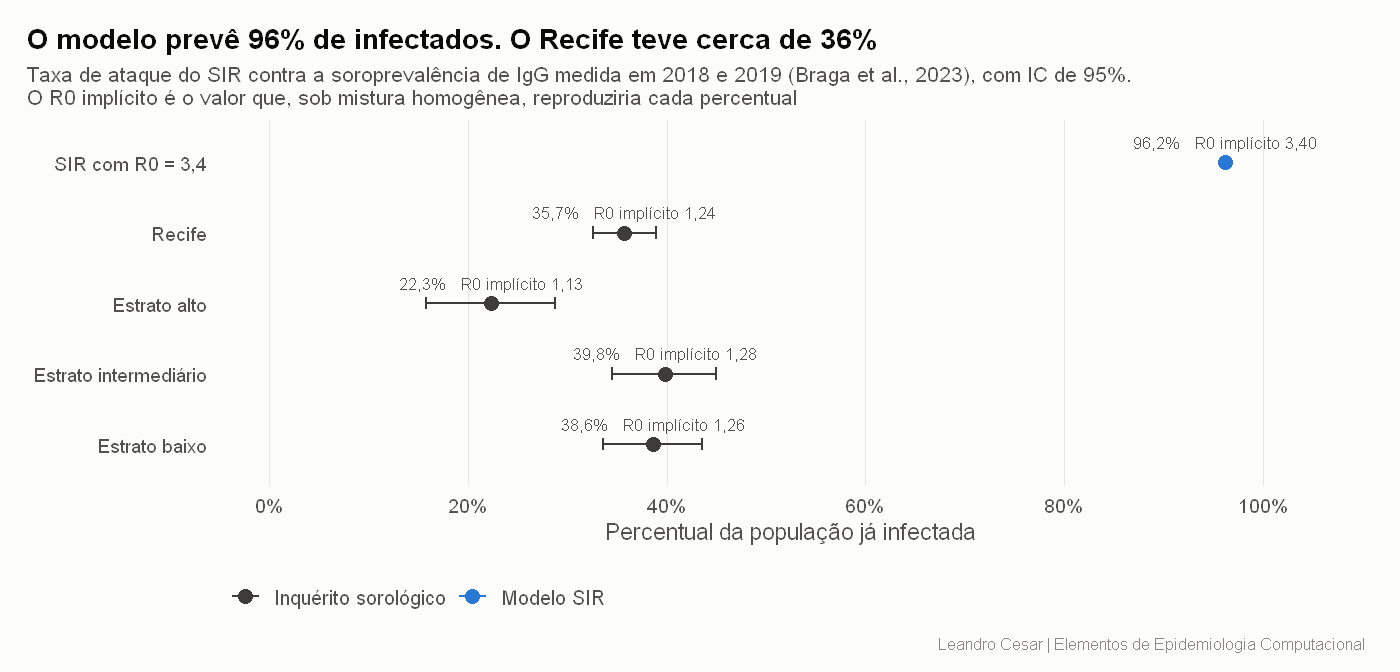

In [19]:
tamanho_figura(10, 4.8)
sorologia <- rbind(
  data.frame(estrato = sprintf("SIR com R0 = %s", num_br(CHIKV$R0, 1)),
             prevalencia = resumo$taxa_ataque, ic_inf = NA, ic_sup = NA, fonte = "Modelo"),
  data.frame(SOROLOGIA, fonte = "Braga et al. (2023)")
)
sorologia$R0_implicito <- r0_implicito(sorologia$prevalencia)
figura_sorologia(sorologia)

### 6.2 As hipóteses que produzem essas distâncias

**O mosquito não existe no modelo.** A transmissão passa pelo *Aedes aegypti*, e o ciclo inclui a
incubação extrínseca, os dias em que o vírus se multiplica no mosquito antes de ele poder transmitir. Ao
comprimir esse ciclo num único β, o modelo perde a densidade de mosquitos, a sazonalidade e a
possibilidade de representar o controle vetorial como ação sobre a população de mosquitos.

**Não há compartimento de expostos.** Entre a picada e o início da viremia há uma latência de cerca de 3
dias (Rudolph et al., 2014). No SIR, quem é infectado transmite na hora, o que acelera o surto.

**A mistura homogênea não descreve o Recife.** O modelo supõe que qualquer suscetível tem a mesma chance de
encontrar qualquer infectado. Numa cidade em que saneamento, armazenamento de água e densidade domiciliar
variam muito entre bairros, a transmissão se concentra em alguns lugares, como mostram os estratos do
inquérito. É a lacuna que mais pesa no tamanho do surto.

**A população é fechada.** Não há nascimentos, óbitos nem mobilidade. O Recife é o centro de uma região
metropolitana de mais de 4 milhões de habitantes, com deslocamento diário intenso.

**Subnotificação e confusão diagnóstica.** Em 2015 e 2016 circulavam dengue, zika e chikungunya ao mesmo
tempo, com quadros parecidos, e muitas infecções por chikungunya passam sem sintomas fortes. A comparação
com a série de casos exige uma fração de notificação.

**O compartimento R esconde a cronificação.** Na revisão de Paixão et al. (2018), 43 por cento dos
pacientes não estavam recuperados três meses depois da infecção. Para o modelo essas pessoas estão em R,
mas para o sistema de saúde continuam doentes.

**As taxas são constantes.** Sem β variando no tempo, o modelo não representa a estação do ano. A
extensão da seção 5.4 só muda β uma vez, numa data escolhida.

### Para onde o modelo cresce

O notebook 02 acrescenta o mosquito e a latência, no modelo SEIR-SEI sugerido pela professora, e compara
os dois modelos com a série do Recife. As lacunas restantes viram objetivos da proposta de projeto:
calibrar o modelo com a série de casos e uma fração de notificação, incluir a sazonalidade e separar a
população em grupos para representar a heterogeneidade.

## Referências

- AUERSWALD, H. et al. Broad and long-lasting immune protection against various Chikungunya genotypes
  demonstrated by participants in a cross-sectional study in a Cambodian rural community. *Emerging
  Microbes & Infections*, v. 7, 13, 2018.
- BOWMAN, L. R.; DONEGAN, S.; McCALL, P. J. Is dengue vector control deficient in effectiveness or
  evidence? Systematic review and meta-analysis. *PLoS Neglected Tropical Diseases*, v. 10, n. 3, e0004551,
  2016.
- BRAGA, C. et al. Seroprevalence of Dengue, Chikungunya and Zika at the epicenter of the congenital
  microcephaly epidemic in Northeast Brazil: a population-based survey. *PLoS Neglected Tropical
  Diseases*, v. 17, n. 7, e0011270, 2023.
- CENTERS FOR DISEASE CONTROL AND PREVENTION. *Clinical Features of Dengue*. Atlanta, 2026.
- HAIDER, N. et al. Basic reproduction number of chikungunya virus transmitted by *Aedes* mosquitoes.
  *Emerging Infectious Diseases*, v. 26, n. 10, p. 2429 a 2431, 2020.
- IBGE. *Censo Demográfico 2022*. Rio de Janeiro: IBGE, 2023.
- KERMACK, W. O.; McKENDRICK, A. G. A contribution to the mathematical theory of epidemics. *Proceedings
  of the Royal Society A*, v. 115, n. 772, p. 700 a 721, 1927.
- MAGALHAES, T. et al. Zika virus displacement by a chikungunya outbreak in Recife, Brazil. *PLoS
  Neglected Tropical Diseases*, v. 11, n. 11, e0006055, 2017.
- MANORE, C. A. et al. Comparing dengue and chikungunya emergence and endemic transmission in *A. aegypti*
  and *A. albopictus*. *Journal of Theoretical Biology*, v. 356, p. 174 a 191, 2014.
- NITATPATTANA, N. et al. Long-term persistence of Chikungunya virus neutralizing antibodies in human
  populations of North Eastern Thailand. *Virology Journal*, v. 11, 183, 2014.
- PAIXÃO, E. S. et al. Chikungunya chronic disease: a systematic review and meta-analysis. *Transactions
  of the Royal Society of Tropical Medicine and Hygiene*, v. 112, n. 7, p. 301 a 316, 2018.
- RUDOLPH, K. E. et al. Incubation periods of mosquito-borne viral infections: a systematic review.
  *American Journal of Tropical Medicine and Hygiene*, v. 90, n. 5, p. 882 a 891, 2014.
- SMITH, D. L. et al. Ross, Macdonald, and a theory for the dynamics and control of mosquito-transmitted
  pathogens. *PLoS Pathogens*, v. 8, n. 4, e1002588, 2012.
- SOETAERT, K.; PETZOLDT, T.; SETZER, R. W. Solving differential equations in R: package deSolve.
  *Journal of Statistical Software*, v. 33, n. 9, 2010.
- SRIKIATKHACHORN, A. et al. Resolution of a chikungunya outbreak in a prospective cohort, Cebu,
  Philippines, 2012 a 2014. *Emerging Infectious Diseases*, v. 22, n. 10, p. 1852 a 1854, 2016.
- WORLD HEALTH ORGANIZATION. *Chikungunya fact sheet*. Genebra: OMS, 2025.